<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/HybridQNN_VehicularIDS_Zhou2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum neural network for vehicular (CAN bus) intrusion detection: Zhou et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Jianhua Zhou, Yueheng Liu, Sifan Li, Yue Cao, Wenkai Chen and Naveed Ahmed,
> "Vehicular Intrusion Detection System Based on Hybrid Quantum Neural Networks",
> *2024 IEEE Global Communications Conference (GLOBECOM)*, pp. 4185-4190, 2024.
> DOI: [10.1109/GLOBECOM52923.2024.10901777](https://doi.org/10.1109/GLOBECOM52923.2024.10901777)

**What the notebook does.**
1. Downloads the public HCRL **Car-Hacking dataset** (the data the paper used: normal driving plus DoS, fuzzy, gear-spoofing and RPM-spoofing
   injections recorded from a real car through the OBD-II port), turns every CAN message into the paper's **49-bit vector**
   (3 hexadecimal ID digits one-hot encoded, plus the DLC) and stacks **64 messages** into one 64 x 49 sample.
2. Builds the paper's **hybrid quantum neural network (HQNN)**: a classical network with multi-head attention, a Conv1D layer, batch
   normalisation, an FNet layer and residual connections, in which a **4-qubit parameterised quantum circuit (PQC)** is called for every
   time step of every residual "Block". The circuit is simulated exactly, written twice (a fast PyTorch statevector simulator that is
   trained, and a PennyLane QNode that is drawn) and the notebook **asserts that both give the same numbers and gradients**.
3. Trains the HQNN, the paper's three ablations (without QNN, without FNet, without CNN), one extra ablation that replaces the quantum
   circuit by a small classical layer, plus Decision Tree, Random Forest, XGBoost, Logistic Regression, an RBF-SVM, an LSTM, a CNN and a
   Transformer on **exactly the same inputs**, and prints the paper's Tables I and II next to the numbers obtained here, with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU runtime** and use *Runtime -> Run all*. The first cell installs PennyLane
(PyTorch, scikit-learn and XGBoost are preinstalled on Colab). No GPU, no quantum-cloud account and no token are needed: the dataset is
public and is downloaded by the notebook (roughly 70 MB from a GitHub mirror plus two streamed passes over the official 1 GB Dropbox
archive; the large CSV files are parsed one by one into small caches and deleted at once).

**Runtime.** `FAST_MODE = True` (a few thousand windows, 4 epochs, 1 seed, only the first 800,000 messages of each capture) is a class demo that
runs in roughly 10 minutes on an idle machine. `FAST_MODE = False` follows the paper's sample sizes (7,812 samples, 7,030 train / 782 test) and takes
roughly one to one and a half hours on a laptop CPU (the exact time of the last full run is printed at the end of the notebook).

**What you get at the end.** The real dataset in pictures, the circuit that is actually executed, a re-drawn Table I, Table II, confusion matrix (Fig. 8)
and ROC curve (Fig. 9), the loss curves behind the "faster convergence" claim, and an honest verdict on what could and could not be reproduced.

## The paper in one page

**Problem.** The CAN bus of a car has no authentication, so an attacker who can inject frames can flood it (DoS), send random messages
(fuzzy) or replay forged gear / RPM messages. A vehicle intrusion detection system (IDS) must decide, in real time, whether the recent traffic
is *normal* or an *attack*. Large deep models are accurate but slow; the paper uses a small quantum circuit inside a classical network "to
compress certain complex non-linear functions" and to cut inference time.

**Decision.** Binary: a window of 64 consecutive CAN messages is *normal* or *attack*.

**Data (Section IV-A).** HCRL Car-Hacking dataset: Normal, Gear spoofing, RPM spoofing, Fuzzy and DoS. The 3-digit hexadecimal ID of each message
is encoded as 3 one-hot vectors of 16 (48 bits) and combined with the DLC to a **49-bit vector**; a window of **T = 64** messages gives a
**64 x 49** sample. Labels are binarised (0 = attack, 1 = normal). After preprocessing there are **7,812 samples**, split 9 : 1 into
**7,030 train and 782 test**.

**Method (Section III, Figs. 4 to 7).**
* Quantum layer: encoding `Ry(f(x))|0>` with `f(x) = arcsin(x)` on **4 qubits**, then a PQC made only of `Ry(theta)` gates and a ring of CNOTs
  (each qubit to its neighbour, the last to the first), **2 PQC layers**, and a measurement of **<Z> on all 4 qubits**.
* Classical network: preprocessed 64 x 49 tensor -> fully connected layers -> 64 x 4 tensor -> **3 residual "Blocks"** -> flatten (256) ->
  fully connected layer (128, ReLU) -> dropout -> fully connected layer (2 classes).
  A Block is: multi-head attention (2 heads) -> Conv1D (kernel 3, stride 1, ReLU) -> batch normalisation -> QNN layer (applied to the 4 features of
  every one of the 64 time steps), and `Output = FNet(Input) + y + Input` where `y` is the QNN output.
* Metrics: accuracy, precision, recall, F1, ROC curve; inference time for the first 5 test samples (repeated 50 times).

**Claims (Tables I and II).**

| Model | Accuracy % | Recall % | Precision % | F1 | Time (ms, 5 samples) |
|---|---|---|---|---|---|
| DT | 88.11 | 86.14 | 83.65 | 0.8488 | - |
| RF | 94.12 | 98.54 | 86.54 | 0.9215 | - |
| XGBoost | 94.12 | 91.35 | 93.75 | 0.9253 | - |
| LR | 95.52 | 88.78 | 100.00 | 0.9406 | - |
| LSTM | 62.66 | 6.73 | 95.45 | 0.1257 | 278.9 |
| CNN | 82.10 | 55.13 | 100.00 | 0.7108 | 174.7 |
| Transformer | 93.09 | 82.69 | 100.00 | 0.9052 | 269.5 |
| baseline [12] (multi-scale feature fusion) | 100.00 | 100.00 | 100.00 | 1.0000 | 622.9 |
| **HQNN (ours)** | **98.47** | **96.15** | **100.00** | **0.9804** | **485.0** |
| ablation: without QNN | 91.43 | 78.85 | 99.60 | 0.8801 | 180.7 |
| ablation: without FNet | 91.05 | 77.56 | 100.00 | 0.8736 | 223.2 |
| ablation: without CNN | 81.20 | 55.13 | 96.09 | 0.7006 | 223.5 |

The paper concludes that the HQNN beats all single-architecture and tree-based models, that each of QNN / FNet / CNN is indispensable,
that it reaches nearly the accuracy of the (classical, larger) baseline [12] with a shorter inference time, and (abstract) that it
"improves detection time and convergence speed".

**A reading of the paper's own numbers.** Table I is internally consistent only if the *positive* class of precision / recall is the class labelled 1,
i.e. **normal** (the paper binarises "0 = attack, 1 = normal"). For example LR: accuracy 95.52 % of 782 test samples = 35 errors; recall 88.78 % with
precision 100 % means 35 false negatives among 312 positives (277/312 = 88.78 %), and for the HQNN 12 errors, 300/312 = 96.15 %. So the test set holds
**312 normal and 470 attack windows (about 60 % attack)** and every error of the HQNN is a *normal* window flagged as attack. This notebook therefore
reports precision, recall and F1 **both** with the paper's convention (normal = positive, used in the comparison) **and** with attack as the positive class.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | not stated | **PyTorch + PennyLane 0.45**. The 4-qubit circuit is a PennyLane QNode (drawn, and used in an equivalence test); training uses an *exact* PyTorch statevector simulation of the same circuit (verified against the QNode on values and gradients) so that it can be run on 64 x 64 x batch circuits |
| Raw data | Car-Hacking dataset [13] | HCRL Car-Hacking: `DoS`, `Fuzzy`, `gear`, `RPM` capture files, original labels `R` (normal) / `T` (injected). The separate `normal_run_data` capture is not used: every attack file also contains plenty of normal traffic |
| Window label | not stated | a window of 64 consecutive, non-overlapping messages is *attack* if **any** message in it is an injected one (`# CHOICE:`) |
| Sampling | 7,812 samples after preprocessing, how drawn not stated | 7,812 windows drawn at random: **60 % attack** (so that the test set matches the 312 / 470 split derived from Table I), spread equally over the four attack types, and 40 % normal windows spread equally over the four files (`# CHOICE:`) |
| Split | 9 : 1 (7,030 / 782), random | the same: stratified random split by traffic class, `random_state=SEED`. A second, harsher **block-wise temporal split** (whole contiguous stretches of every capture are held out, neighbouring stretches dropped) is added as a robustness check |
| Message encoding | 3 one-hot vectors (48 bits) + DLC = 49 | exactly that; the DLC enters as `DLC / 8` (`# CHOICE:` scale). The 8 data bytes are **not** used by the paper's encoding and are not used here |
| FC layers before the Blocks | "fully connected layers" to 64 x 4 | `Linear(49,16) - ReLU - Linear(16,4)` applied to every time step (`# CHOICE:`) |
| Encoding function | `f(x) = arcsin(x)` | `arcsin(tanh(x))`. `arcsin` is only defined on [-1, 1] but the batch-normalised features are not bounded; `tanh` squashes them first (`# CHOICE:`; the derivative of `arcsin(tanh(x))` is `sech(x)`, finite everywhere) |
| PQC | `Ry(theta)` + CNOT ring, 2 layers | exactly that: per layer one `Ry(theta)` on each of the 4 qubits and the CNOT ring 0-1, 1-2, 2-3, 3-0. The two layers have **separate** trainable angles (`# CHOICE:` the paper says "two identical quantum circuits are concatenated"); 8 parameters per QNN, initialised uniformly in [0, 2 pi) |
| Measurement | <Z> on every qubit | the same (4 outputs in [-1, 1] per time step) |
| Block details | MHA (2 heads), Conv1D (k=3, stride 1, "padding 2"), BN, QNN, FNet | MHA with 2 heads (embedding 4); Conv1D(4,4,k=3,stride 1) with **same padding 1** so that the 64 x 4 shape is kept (padding 2 would lengthen the sequence; `# CHOICE:`); BN over the 4 channels; QNN; `FNet(x)` = real part of the orthonormal 2-D FFT over (time, feature) of the Block input. `Output = FNet(Input) + y + Input` (`# CHOICE:` the "(+)" is an element-wise sum) |
| Skip over the 3 Blocks | "skip connection being the reduced-dimensional input" | `out = Block3(Block2(Block1(z))) + z` with `z` the 64 x 4 tensor |
| Head | flatten (256) -> FC 128 ReLU -> dropout -> FC 2 | the same, dropout 0.3 (`# CHOICE:` rate not given) |
| Training | optimiser, loss, epochs, batch size not stated | cross-entropy, Adam (lr 1e-3), batch 64, 10 epochs (full run; FAST_MODE: 4 epochs), no early stopping, **no model selection on the test set** (the model after the last epoch is evaluated) |
| Classical baselines | DT, RF, XGBoost, LR, LSTM, CNN, Transformer: settings not given | flattened 64 x 49 = 3,136 inputs for DT / RF / XGBoost / LR / SVC; LSTM, CNN and Transformer see the 64 x 49 sequence; small standard architectures, same epochs as the HQNN (`# CHOICE:`) |
| Baseline [12] | multi-scale feature fusion model | **cannot be reproduced**: it is another paper (ICC 2024) and its architecture is not given here |
| Timing | first 5 test samples, 50 repetitions, on unknown hardware | the same protocol on this CPU (PyTorch simulator, not comparable in absolute terms) |
| Repeats | one run | HQNN and "without QNN": 2 seeds; the other ablations and the deep baselines 1 seed (mean +/- std where more than one) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, xgboost and PyTorch.
# The pip line only runs on Colab or where PennyLane is missing; a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
if importlib.util.find_spec("xgboost") is None:
    %pip install -q xgboost
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False          # True: class demo in well under 10 minutes. False: the paper's sample sizes and a longer budget (about 1 to 1.5 h on a CPU).

SEED          = 42             # CHOICE: the paper gives no seed
DATA_DIR      = "car_hacking_data"   # downloads are parsed into small caches here (nothing is written anywhere else)
LOCAL_CSV_DIR = ""             # optional: folder that already holds DoS_dataset.csv, Fuzzy_dataset.csv, gear_dataset.csv, RPM_dataset.csv
IBM_TOKEN     = ""             # not used: the paper simulated the circuit and so does this notebook
# No Hugging Face / API token is needed: the Car-Hacking dataset is public (GitHub mirror + official HCRL Dropbox folder).

# --- data (Section IV-A) ---
WINDOW        = 64             # paper: time window T = 64 messages
ATTACK_SHARE  = 0.60           # CHOICE: share of attack windows (derived from the paper's Table I: 312 normal / 470 attack in the test set)
if FAST_MODE:
    N_SAMPLES, N_TEST = 2_000, 200          # paper: 7,812 samples, 7,030 train / 782 test
    MAX_ROWS      = 800_000                 # parse only the first 800,000 messages of every capture (None = the whole file)
    EPOCHS, BATCH = 4, 64
    SEEDS, ABL_SEEDS, DL_SEEDS = [0], [0], [0]
    SVC_MAX_TRAIN = 1_500
else:
    N_SAMPLES, N_TEST = 7_812, 782
    MAX_ROWS      = None
    EPOCHS, BATCH = 10, 64                   # paper: not stated
    SEEDS, ABL_SEEDS, DL_SEEDS = [0, 1], [0], [0]
    SVC_MAX_TRAIN = None
LR            = 1e-3           # CHOICE: Adam learning rate (paper: not stated)
DROPOUT       = 0.3            # CHOICE: paper: "a Dropout layer", rate not stated
T_BLOCKS, T_MOD, T_TEST_RES = 40, 8, 3          # temporal robustness split: every capture is cut into 40 contiguous time blocks; blocks 3, 11, 19, 27, 35 are test, their neighbours are dropped
TORCH_THREADS = 1              # the tensors are tiny: one thread is fastest (and kind to a shared machine)
print("FAST_MODE =", FAST_MODE, "| samples", N_SAMPLES, "| test", N_TEST, "| epochs", EPOCHS, "| seeds", SEEDS)

FAST_MODE = False | samples 7812 | test 782 | epochs 10 | seeds [0, 1]


In [3]:
import os, sys, time, math, struct, zlib, zipfile, shutil, warnings, platform
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, pennylane as qml, xgboost
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve, roc_auc_score
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
T_NOTEBOOK_START = time.time()

np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(TORCH_THREADS)
print("python", sys.version.split()[0], "|", platform.system(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| xgboost", xgboost.__version__)

python 3.12.10 | Windows | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1


## 1. The data: the HCRL Car-Hacking dataset

The Car-Hacking dataset (Song, Kim and Kim, Hacking and Countermeasure Research Lab, Korea University, 2018) was recorded through the OBD-II port of a
real car while the researchers injected messages. Every capture is a CSV without header, one CAN frame per line:

`timestamp, CAN ID (hex), DLC, DATA[0..DLC-1] (hex), flag`

where the last field is **`R`** (a normal frame) or **`T`** (an injected frame). There are four attack captures:

| File | Attack | What is injected |
|---|---|---|
| `DoS_dataset.csv` | DoS | message `0x000` every 0.3 ms |
| `Fuzzy_dataset.csv` | fuzzy | messages with random ID and random payload every 0.5 ms |
| `gear_dataset.csv` | gear spoofing | forged messages with the gear-information ID every 1 ms |
| `RPM_dataset.csv` | RPM spoofing | forged messages with the RPM-information ID every 1 ms |

`DoS` and `Fuzzy` are taken from a 66 MB GitHub mirror; `gear` and `RPM` are streamed from the official Dropbox folder of the lab (the notebook reads the
1 GB zip as a stream and keeps only the one member it needs; the mirror has no gear / RPM files). Each CSV is parsed once into three small arrays
(ID, DLC, flag) cached in `DATA_DIR`, and the CSV is deleted immediately.

In [4]:
GITHUB_ZIP  = "https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Dataset-1.zip"   # 66 MB mirror: DoS, Fuzzy, normal_run_data
DROPBOX_ZIP = ("https://www.dropbox.com/scl/fo/9rwsf9pclhvv9xxloojom/AF7JeRW893grZkigkulkAHk"
               "?rlkey=3h6zamu3kc262lrnipu5qden8&dl=1")      # official HCRL folder (about 1 GB; gear and RPM are only here)
FAMILIES = ["DoS", "Fuzzy", "gear", "RPM"]
CSV_FILE = {"DoS": "DoS_dataset.csv", "Fuzzy": "Fuzzy_dataset.csv", "gear": "gear_dataset.csv", "RPM": "RPM_dataset.csv"}
MIRROR_HAS = ("DoS", "Fuzzy")
os.makedirs(DATA_DIR, exist_ok=True)
TAG = "all" if MAX_ROWS is None else f"first{MAX_ROWS}"

def _hexval(d):
    d = d.astype(np.int16)
    return np.where(d >= 97, d - 87, np.where(d >= 65, d - 55, d - 48))

def parse_csv(path, max_rows=None, block=16 << 20):
    """Fast vectorised parser for one Car-Hacking CSV (timestamp,ID,DLC,DATA...,flag). Returns, for every line,
    the CAN ID (int16), the DLC (int8) and the flag (int8, 1 = injected 'T', 0 = normal 'R'). Reads the file in 16 MB blocks."""
    ids, dlcs, ys, n_rows, carry = [], [], [], 0, b""
    with open(path, "rb") as f:
        while True:
            blk = f.read(block)
            if blk:
                data = carry + blk
                k = data.rfind(b"\n")
                if k < 0:
                    carry = data; continue
                carry, data = data[k + 1:], data[:k + 1]
            else:
                data, carry = carry, b""
                if data and not data.endswith(b"\n"): data += b"\n"
            if data:
                a = np.frombuffer(data, np.uint8)
                nl = np.flatnonzero(a == 10)                                  # line ends
                cm = np.flatnonzero(a == 44)                                  # commas
                starts = np.concatenate(([0], nl[:-1] + 1))
                i1 = np.searchsorted(cm, starts)                              # first comma of every line
                ok = i1 + 2 < len(cm)
                valid = ok & (cm[np.minimum(np.where(ok, i1, 0) + 2, len(cm) - 1)] < nl)
                cs = i1[valid]
                c1, c2 = cm[cs], cm[cs + 1]
                val = np.zeros(len(c1), np.int64)
                for j in range(4):                                            # the ID is written with 4 hex digits
                    pos = c1 + 1 + j
                    val = np.where(pos < c2, val * 16 + _hexval(a[np.minimum(pos, c2 - 1)]), val)
                dlc = a[c2 + 1].astype(np.int16) - 48
                e = nl[valid]
                fch = np.where(a[e - 1] == 13, a[e - 2], a[e - 1])            # last character = flag (tolerate CRLF)
                ids.append(val.astype(np.int16)); dlcs.append(dlc.astype(np.int8)); ys.append((fch == 84).astype(np.int8))
                n_rows += len(c1)
            if not blk or (max_rows and n_rows >= max_rows): break
    ids, dlcs, ys = np.concatenate(ids), np.concatenate(dlcs), np.concatenate(ys)
    if max_rows: ids, dlcs, ys = ids[:max_rows], dlcs[:max_rows], ys[:max_rows]
    return ids, dlcs, ys

def download(url, dest, chunk=1 << 20):
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as fh:
            for part in r.iter_content(chunk):
                fh.write(part)

def stream_member(url, wanted, out_dir, log=print):
    """Stream a (Dropbox) zip over HTTP and write only the member called `wanted`; everything before it is read and thrown away.
    Dropbox zips store members uncompressed with 'data descriptors' (sizes come after the data), so the end of a member is found by
    scanning for the descriptor signature and checking that its size field equals the number of bytes seen."""
    r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
    it = r.iter_content(1 << 20); buf = bytearray(); dest = None
    def need(n):
        while len(buf) < n:
            try: buf.extend(next(it))
            except StopIteration: return False
        return True
    while need(30) and bytes(buf[:4]) == b"PK\x03\x04":
        ver, flag, comp, mt, md_, crc, csz, usz, nl, el = struct.unpack("<HHHHHIIIHH", bytes(buf[4:30]))
        need(30 + nl + el)
        name = bytes(buf[30:30 + nl]).decode("utf-8", "replace"); del buf[:30 + nl + el]
        keep = os.path.basename(name).lower() == wanted.lower()
        fh = open(os.path.join(out_dir, wanted), "wb") if keep else None
        if comp == 8:                                                         # deflate
            d = zlib.decompressobj(-15)
            while not d.eof:
                if not buf and not need(1): raise IOError("truncated zip")
                chunk = bytes(buf); buf.clear(); out = d.decompress(chunk)
                if fh and out: fh.write(out)
            buf.extend(d.unused_data)
        elif comp == 0 and (flag & 8):                                        # stored, size known only from the descriptor
            written = 0
            while True:
                need(64); k = bytes(buf).find(b"PK\x07\x08"); ok = False
                while k >= 0:
                    if need(k + 16):
                        _, s2, u2 = struct.unpack("<III", bytes(buf[k + 4:k + 16]))
                        if s2 == (written + k) & 0xFFFFFFFF and u2 == s2: ok = True; break
                    k = bytes(buf).find(b"PK\x07\x08", k + 1)
                if ok:
                    if fh: fh.write(bytes(buf[:k]))
                    del buf[:k]; break
                n = max(0, len(buf) - 20)
                if fh and n: fh.write(bytes(buf[:n]))
                written += n; del buf[:n]
                if not need(len(buf) + 1): raise IOError("truncated stored member")
        elif comp == 0:
            left = csz
            while left:
                if not buf: need(1)
                n = min(left, len(buf))
                if fh: fh.write(bytes(buf[:n]))
                del buf[:n]; left -= n
        else:
            raise IOError("unsupported zip layout")
        if fh:
            fh.close(); dest = os.path.join(out_dir, wanted); break
        if flag & 8:
            need(16); del buf[:16 if bytes(buf[:4]) == b"PK\x07\x08" else 12]
    r.close()
    return dest

RAW, MIRROR_ZIP = {}, os.path.join(DATA_DIR, "mirror.zip")
t0 = time.time()
for name in FAMILIES:
    cache = os.path.join(DATA_DIR, f"{name}_{TAG}.npz")
    if not os.path.exists(cache):
        fn, csv, temp = CSV_FILE[name], None, False
        if LOCAL_CSV_DIR and os.path.exists(os.path.join(LOCAL_CSV_DIR, fn)):
            csv = os.path.join(LOCAL_CSV_DIR, fn)
        if csv is None and name in MIRROR_HAS:
            try:
                if not os.path.exists(MIRROR_ZIP):
                    print("downloading the 66 MB GitHub mirror ...", flush=True); download(GITHUB_ZIP, MIRROR_ZIP)
                with zipfile.ZipFile(MIRROR_ZIP) as z, open(os.path.join(DATA_DIR, fn), "wb") as dst:
                    with z.open(fn) as src: shutil.copyfileobj(src, dst, 1 << 20)
                csv, temp = os.path.join(DATA_DIR, fn), True
            except Exception as e:
                print("  GitHub mirror failed:", repr(e)); csv = None
        if csv is None:
            print(f"streaming {fn} from the official HCRL Dropbox folder ...", flush=True)
            csv, temp = stream_member(DROPBOX_ZIP, fn, DATA_DIR), True
            if csv is None: raise RuntimeError(f"{fn} not found in the Dropbox archive; set LOCAL_CSV_DIR to a folder that holds it")
        cid, dlc, y = parse_csv(csv, MAX_ROWS)
        np.savez_compressed(cache, cid=cid, dlc=dlc, y=y)
        if temp and os.path.exists(csv): os.remove(csv)                       # big CSV is not needed any more
        print(f"{name:6s}: parsed {len(y):>9,} messages ({int(y.sum()):,} injected) in {time.time() - t0:.0f} s (cumulative)", flush=True)
    z = np.load(cache)
    RAW[name] = dict(cid=z["cid"].astype(np.int32), dlc=z["dlc"], y=z["y"])
if os.path.exists(MIRROR_ZIP): os.remove(MIRROR_ZIP)                         # the 66 MB zip is not needed any more
print(f"data ready in {time.time() - t0:.0f} s | cache size on disk: {sum(os.path.getsize(os.path.join(DATA_DIR, f)) for f in os.listdir(DATA_DIR)) / 1e6:.1f} MB")

downloading the 66 MB GitHub mirror ...


DoS   : parsed 3,665,771 messages (587,521 injected) in 9 s (cumulative)


Fuzzy : parsed 3,838,860 messages (491,847 injected) in 17 s (cumulative)


streaming gear_dataset.csv from the official HCRL Dropbox folder ...


gear  : parsed 4,443,142 messages (597,252 injected) in 51 s (cumulative)


streaming RPM_dataset.csv from the official HCRL Dropbox folder ...

RPM   : parsed 4,621,702 messages (654,897 injected) in 75 s (cumulative)


data ready in 75 s | cache size on disk: 4.8 MB


## 2. From messages to 64 x 49 samples (Section IV-A)

For every message the **ID** (11 bits, written as 3 hexadecimal digits) becomes three one-hot vectors of length 16, i.e. 48 bits, and the **DLC** is appended: 49 numbers.
64 consecutive messages make one sample of shape 64 x 49. A window is labelled **attack** if it contains at least one injected message.

The paper does not say how its 7,812 samples were drawn. Here: non-overlapping windows are cut from each of the four capture files, and
`N_SAMPLES` windows are drawn at random with `ATTACK_SHARE` = 60 % attack windows (spread equally over DoS / fuzzy / gear / RPM) and 40 % normal windows
(spread equally over the four files). The 90 : 10 split is stratified by traffic class.

In [5]:
def encode(ids, dlc):
    """ids [N,T] CAN IDs, dlc [N,T] -> float32 [N,T,49]: 3 hex digits one-hot (3 x 16) + DLC/8"""
    ids = ids.astype(np.int32)
    out = np.zeros(ids.shape + (49,), np.float32)
    n_idx, t_idx = np.indices(ids.shape)
    for j, sh in enumerate((8, 4, 0)):
        out[n_idx, t_idx, 16 * j + ((ids >> sh) & 15)] = 1.0
    out[..., 48] = dlc / 8.0                                                   # CHOICE: DLC scaled to [0, 1]
    return out

FEATURE_NAMES = [f"id_hex{d}={h:x}" for d in (2, 1, 0) for h in range(16)] + ["DLC/8"]
rng_s = np.random.default_rng(SEED)

windows = {}
for name in FAMILIES:
    R = RAW[name]; n_win = len(R["y"]) // WINDOW
    yw = R["y"][:n_win * WINDOW].reshape(n_win, WINDOW).any(1)
    windows[name] = dict(att=np.flatnonzero(yw), norm=np.flatnonzero(~yw), n_win=n_win)

def split_quota(total, parts):
    q = [total // parts] * parts
    for i in range(total - sum(q)): q[i] += 1
    return q

n_att = int(round(N_SAMPLES * ATTACK_SHARE)); n_nor = N_SAMPLES - n_att
sel_name, sel_idx, sel_cls = [], [], []
for name, qa, qn in zip(FAMILIES, split_quota(n_att, 4), split_quota(n_nor, 4)):
    W_ = windows[name]
    a = rng_s.choice(W_["att"], min(qa, len(W_["att"])), replace=False)
    nrm = rng_s.choice(W_["norm"], min(qn, len(W_["norm"])), replace=False)
    sel_name += [name] * (len(a) + len(nrm)); sel_idx += list(a) + list(nrm)
    sel_cls += [name] * len(a) + ["Normal"] * len(nrm)
sel_name, sel_idx, sel_cls = np.array(sel_name), np.array(sel_idx), np.array(sel_cls)
order = rng_s.permutation(len(sel_idx)); sel_name, sel_idx, sel_cls = sel_name[order], sel_idx[order], sel_cls[order]

ids_w = np.zeros((len(sel_idx), WINDOW), np.int32); dlc_w = np.zeros((len(sel_idx), WINDOW), np.int8); pos = np.zeros(len(sel_idx))
for i, (nm, w) in enumerate(zip(sel_name, sel_idx)):
    sl = slice(w * WINDOW, (w + 1) * WINDOW)
    ids_w[i], dlc_w[i] = RAW[nm]["cid"][sl], RAW[nm]["dlc"][sl]
    pos[i] = w / windows[nm]["n_win"]                                           # relative position in its capture (for the temporal split)
Xoh = encode(ids_w, dlc_w)                       # [N, 64, 49]
y_all = (sel_cls != "Normal").astype(np.int64)   # 1 = attack
Xflat = Xoh.reshape(len(Xoh), -1)                # [N, 3136] view for the classical machine-learning models
del ids_w, dlc_w

idx_all = np.arange(len(y_all))
idx_tr, idx_te = train_test_split(idx_all, test_size=N_TEST, stratify=sel_cls, random_state=SEED)
blk = np.minimum((pos * T_BLOCKS).astype(int), T_BLOCKS - 1) % T_MOD                       # position of the window inside its 8-block cycle
idx_te_t = np.flatnonzero(blk == T_TEST_RES)                                              # whole contiguous time blocks held out
idx_tr_t = np.flatnonzero((blk != T_TEST_RES) & (blk != (T_TEST_RES - 1) % T_MOD) & (blk != (T_TEST_RES + 1) % T_MOD))   # neighbouring blocks dropped
print(f"samples {Xoh.shape} | train {len(idx_tr)} / test {len(idx_te)} (paper: 7,030 / 782) | attack share {y_all.mean():.1%}")
print(f"test set: {int((y_all[idx_te]==0).sum())} normal / {int((y_all[idx_te]==1).sum())} attack windows (paper, derived from Table I: 312 / 470)")
print(f"temporal split: train {len(idx_tr_t)} / test {len(idx_te_t)} windows")
display(pd.crosstab(pd.Series(sel_cls, name="window class"), pd.Series(np.where(np.isin(np.arange(len(y_all)), idx_te), "test", "train"), name="split")))

samples (7812, 64, 49) | train 7030 / test 782 (paper: 7,030 / 782) | attack share 60.0%


test set: 313 normal / 469 attack windows (paper, derived from Table I: 312 / 470)
temporal split: train 4914 / test 994 windows


split,test,train
window class,,
DoS,117,1055
Fuzzy,117,1055
Normal,313,2812
RPM,117,1054
gear,118,1054


## Dataset Exploration and Visualisation

Everything below is drawn from the **real** Car-Hacking messages and windows; nothing is simulated.

original files (message level, flag R = normal, T = injected):


,file,messages,R_normal,T_injected,injected_share,distinct_IDs,IDs_in_injected,windows_64,attack_windows
0,DoS_dataset.csv,3665771,3078250,587521,0.160,27,1,57277,17128
1,Fuzzy_dataset.csv,3838860,3347013,491847,0.128,2048,2048,59982,20317
2,gear_dataset.csv,4443142,3845890,597252,0.134,26,1,69424,29751
3,RPM_dataset.csv,4621702,3966805,654897,0.142,26,1,72214,32501



sample tensor Xoh: shape (7812, 64, 49) = (windows, 64 messages, 49 features); flattened for classical ML: (7812, 3136)
feature names (49): ['id_hex2=0', 'id_hex2=1', 'id_hex2=2', 'id_hex2=3'] ... ['id_hex2=e', 'id_hex2=f', 'id_hex1=0', 'id_hex1=1'] ... ['id_hex0=e', 'id_hex0=f', 'DLC/8']
original labels: message level {R, T}; window level (this notebook): {'Normal': np.int64(3125), 'Fuzzy': np.int64(1172), 'DoS': np.int64(1172), 'gear': np.int64(1172), 'RPM': np.int64(1171)}
binary label used by the model: 1 = attack ( 4687 ), 0 = normal ( 3125 )


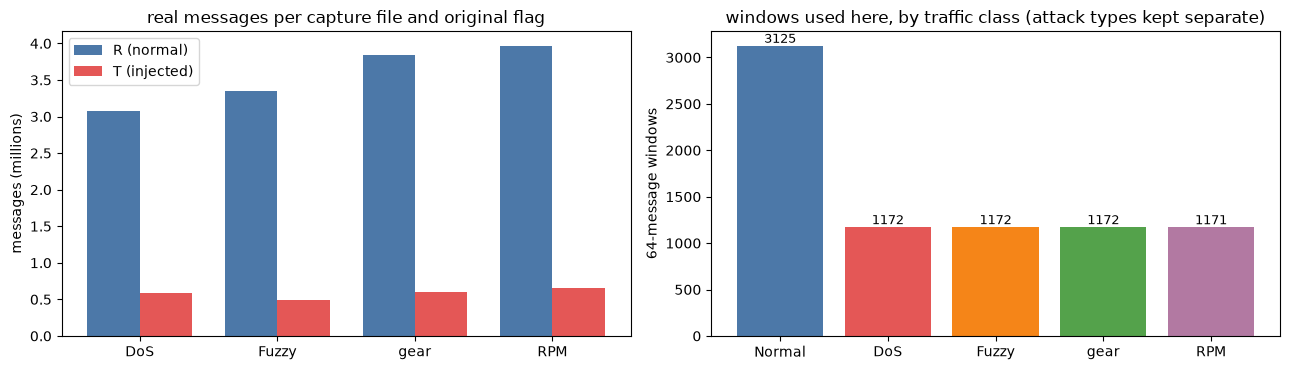

In [6]:
print("original files (message level, flag R = normal, T = injected):")
rows = []
for name in FAMILIES:
    R = RAW[name]
    rows.append(dict(file=CSV_FILE[name], messages=len(R["y"]), R_normal=int((R["y"] == 0).sum()), T_injected=int(R["y"].sum()),
                     injected_share=round(float(R["y"].mean()), 3), distinct_IDs=len(np.unique(R["cid"])),
                     IDs_in_injected=len(np.unique(R["cid"][R["y"] == 1])), windows_64=windows[name]["n_win"],
                     attack_windows=len(windows[name]["att"])))
FILE_TABLE = pd.DataFrame(rows); display(FILE_TABLE)
print(f"\nsample tensor Xoh: shape {Xoh.shape} = (windows, {WINDOW} messages, 49 features); flattened for classical ML: {Xflat.shape}")
print("feature names (49):", FEATURE_NAMES[:4], "...", FEATURE_NAMES[14:18], "...", FEATURE_NAMES[-3:])
print("original labels: message level {R, T}; window level (this notebook):", dict(pd.Series(sel_cls).value_counts()))
print("binary label used by the model: 1 = attack (", int(y_all.sum()), "), 0 = normal (", int((1 - y_all).sum()), ")")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
w = 0.38; xs = np.arange(len(FAMILIES))
ax[0].bar(xs - w / 2, FILE_TABLE["R_normal"] / 1e6, w, label="R (normal)", color="#4c78a8")
ax[0].bar(xs + w / 2, FILE_TABLE["T_injected"] / 1e6, w, label="T (injected)", color="#e45756")
ax[0].set_xticks(xs); ax[0].set_xticklabels(FAMILIES); ax[0].set_ylabel("messages (millions)"); ax[0].legend()
ax[0].set_title("real messages per capture file and original flag")
CLASSES = ["Normal"] + FAMILIES
COL = {"Normal": "#4c78a8", "DoS": "#e45756", "Fuzzy": "#f58518", "gear": "#54a24b", "RPM": "#b279a2"}
cnt = pd.Series(sel_cls).value_counts().reindex(CLASSES)
ax[1].bar(CLASSES, cnt.values, color=[COL[c] for c in CLASSES])
for i, v in enumerate(cnt.values): ax[1].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax[1].set_ylabel("64-message windows"); ax[1].set_title("windows used here, by traffic class (attack types kept separate)")
plt.tight_layout(); plt.show()

explained variance of the two PCA axes: [0.042 0.019]


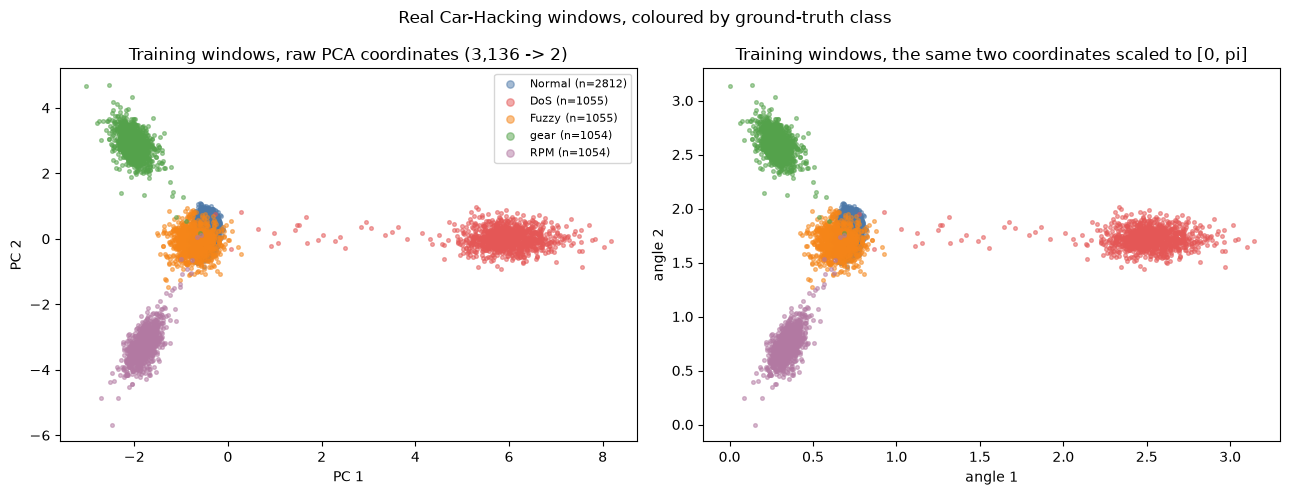

In [7]:
# 2-D scatter of the real windows, coloured by the ground-truth traffic class. PCA is fitted on the training split only.
pca2 = PCA(n_components=2, svd_solver="randomized", random_state=SEED).fit(Xflat[idx_tr])
P_tr, P_te = pca2.transform(Xflat[idx_tr]), pca2.transform(Xflat[idx_te])
sc = MinMaxScaler((0, np.pi)).fit(P_tr)                                        # fitted on train; test angles clipped to [0, pi]
A_tr, A_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)
print("explained variance of the two PCA axes:", pca2.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in CLASSES:
    m = sel_cls[idx_tr] == c
    ax[0].scatter(P_tr[m, 0], P_tr[m, 1], s=7, alpha=0.5, color=COL[c], label=f"{c} (n={int(m.sum())})")
    ax[1].scatter(A_tr[m, 0], A_tr[m, 1], s=7, alpha=0.5, color=COL[c])
ax[0].set_title("Training windows, raw PCA coordinates (3,136 -> 2)"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(markerscale=2, fontsize=8)
ax[1].set_title("Training windows, the same two coordinates scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
plt.suptitle("Real Car-Hacking windows, coloured by ground-truth class"); plt.tight_layout(); plt.show()

How to read the two pictures: every point is one real 64-message window. DoS windows are the ones full of the all-zero ID, fuzzy windows contain a
wide spread of random IDs, and gear / RPM windows contain a flood of one forged ID. The first two principal axes already pull the
big groups apart, but the groups overlap in the middle: a window that contains only a few injected messages looks almost like normal traffic. That
overlap is where classifiers make their errors. (The paper's quantum circuit does *not* see these coordinates; it sees 4 learned features per message,
see section 6.)

## 3. Classical machine-learning baselines on the same windows

Decision Tree, Random Forest, XGBoost and Logistic Regression (as in Table I), plus an RBF-SVM as an extra kernel baseline, all fitted on the **training
windows only**, on the flattened 64 x 49 = 3,136 inputs (`# CHOICE:` the paper does not say what the tree-based models receive).

**Metrics.** As explained above, the paper's precision / recall / F1 take the class labelled 1 = *normal* as the positive class. The helper below returns both
conventions: `rec_paper`, `prec_paper`, `f1_paper` (normal positive, compared with the paper) and `prec_att`, `rec_att`, `f1_att` (attack positive,
the usual security convention).

In [8]:
def prf(y, p, pos):
    P, R, F, _ = precision_recall_fscore_support(y == pos, p == pos, average="binary", zero_division=0)
    return 100 * P, 100 * R, F

def metrics(y, p):
    """y, p: 1 = attack, 0 = normal. Paper convention: positive = normal."""
    P_n, R_n, F_n = prf(y, p, 0); P_a, R_a, F_a = prf(y, p, 1)
    return dict(acc=100 * float((y == p).mean()), rec_paper=R_n, prec_paper=P_n, f1_paper=F_n, rec_att=R_a, prec_att=P_a, f1_att=F_a)

RESULTS = {}      # name -> list of per-run dicts (metrics, time, params, probabilities, history)
def add_result(name, **kw): RESULTS.setdefault(name, []).append(kw)

def run_ml(name, make, tr, te, split="paper", max_train=None):
    t0 = time.time()
    tr_ = tr if max_train is None or len(tr) <= max_train else np.random.default_rng(SEED).choice(tr, max_train, replace=False)
    m = make().fit(Xflat[tr_], y_all[tr_])
    p = m.predict(Xflat[te])
    score = m.predict_proba(Xflat[te])[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xflat[te])
    add_result(name + ("" if split == "paper" else " [temporal]"), seed=0, split=split, y=y_all[te], pred=p, score=score,
               **metrics(y_all[te], p), secs=time.time() - t0, params=None)
    r = RESULTS[name + ("" if split == "paper" else " [temporal]")][-1]
    print(f"{name:14s} [{split:8s}] acc {r['acc']:6.2f} | paper-convention recall {r['rec_paper']:6.2f} precision {r['prec_paper']:6.2f} F1 {r['f1_paper']:.4f} | {r['secs']:.0f} s")

ML_MODELS = {
    "DT":      lambda: DecisionTreeClassifier(random_state=SEED),
    "RF":      lambda: RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=SEED),
    "XGBoost": lambda: XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0),
    "LR":      lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "SVC (rbf, extra)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED),
}
for nm, mk in ML_MODELS.items():
    run_ml(nm, mk, idx_tr, idx_te, "paper", SVC_MAX_TRAIN if "SVC" in nm else None)

DT             [paper   ] acc  84.65 | paper-convention recall  82.75 precision  79.69 F1 0.8119 | 3 s


RF             [paper   ] acc  98.72 | paper-convention recall  99.04 precision  97.79 F1 0.9841 | 8 s


XGBoost        [paper   ] acc  98.72 | paper-convention recall  99.04 precision  97.79 F1 0.9841 | 26 s


LR             [paper   ] acc  98.85 | paper-convention recall 100.00 precision  97.20 F1 0.9858 | 1 s


SVC (rbf, extra) [paper   ] acc  98.98 | paper-convention recall 100.00 precision  97.51 F1 0.9874 | 104 s


## Quantum Circuit Architecture

The only quantum component of the paper is the **QNN layer** inside every residual Block (Figs. 4 and 5). It is a 4-qubit circuit that is run once for
every one of the 64 time steps of a sample, with the same trainable angles:

1. **Encoding** `U_Enc`: the 4 features of the time step are mapped to angles `f(x) = arcsin(tanh(x))` in (-pi/2, pi/2) and applied as `Ry(f(x_k))|0>` on qubit `k`.
2. **PQC** `U_PQC`: two layers, each one `Ry(theta)` on every qubit followed by the CNOT ring 0->1, 1->2, 2->3, 3->0.
3. **Measurement**: the expectation value of Pauli-Z on every qubit, four numbers in [-1, 1].

Two implementations of exactly this circuit are used. The **PennyLane QNode** below is the reference: it is drawn and used for the equivalence test. The
**PyTorch statevector simulator** `TorchQNN` computes the same thing on whole batches (64 x 64 circuits per training step) and with PyTorch gradients, so that the
network can be trained end to end. Only gates `Ry` and `CNOT` are used, so all amplitudes stay real.

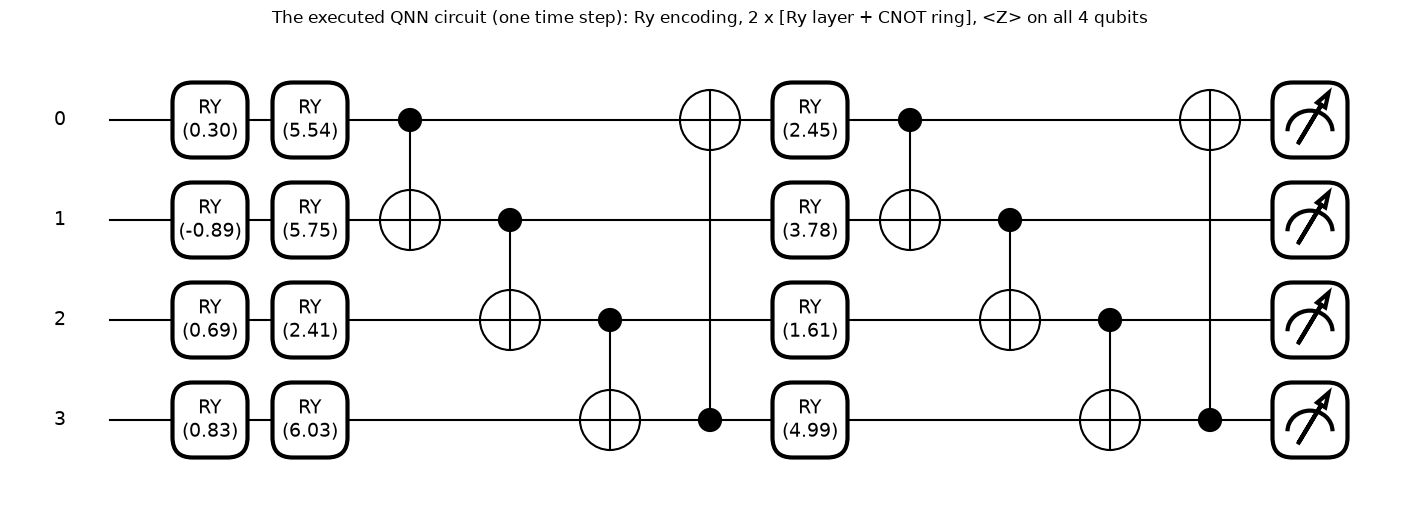

0: ──RY(0.30)───RY(5.54)─╭●───────╭X──RY(2.45)─╭●───────╭X─┤  <Z>
1: ──RY(-0.89)──RY(5.75)─╰X─╭●────│───RY(3.78)─╰X─╭●────│──┤  <Z>
2: ──RY(0.69)───RY(2.41)────╰X─╭●─│───RY(1.61)────╰X─╭●─│──┤  <Z>
3: ──RY(0.83)───RY(6.03)───────╰X─╰●──RY(4.99)───────╰X─╰●─┤  <Z>

qubits: 4 | circuit depth: 11 | gates: 20 {'RY': 12, 'CNOT': 8} | measurements: 4 x <Z>
trainable parameters per QNN layer: 8 (NL=2 layers x 4 qubits); the full network has 3 Blocks = 24 quantum parameters


In [9]:
NQ, NL = 4, 2        # paper: 4 qubits, 2 PQC layers

def ry_mat(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s]), torch.stack([s, c])])

def ring_permutation(n=NQ):
    """permutation matrix of CNOT(0,1) CNOT(1,2) ... CNOT(n-1,0) applied in this order; qubit 0 is the most significant bit (as in PennyLane)"""
    P = torch.zeros(2 ** n, 2 ** n)
    for i in range(2 ** n):
        b = [(i >> (n - 1 - k)) & 1 for k in range(n)]
        for k in range(n): b[(k + 1) % n] ^= b[k]
        P[sum(bit << (n - 1 - k) for k, bit in enumerate(b)), i] = 1.0
    return P

class TorchQNN(nn.Module):
    """Exact statevector simulation of the paper's 4-qubit QNN layer, batched over any leading dimensions."""
    def __init__(self):
        super().__init__()
        self.theta = nn.Parameter(torch.rand(NL, NQ) * 2 * math.pi)          # CHOICE: uniform initial angles in [0, 2 pi)
        self.register_buffer("P", ring_permutation())
        self.register_buffer("Z", torch.tensor([[1 - 2 * ((i >> (NQ - 1 - k)) & 1) for k in range(NQ)] for i in range(2 ** NQ)], dtype=torch.float32))
        self.record = False; self.last_x = None
    def unitary(self):
        U = torch.eye(2 ** NQ, dtype=self.theta.dtype)
        for l in range(NL):
            R = ry_mat(self.theta[l, 0])
            for k in range(1, NQ): R = torch.kron(R, ry_mat(self.theta[l, k]))
            U = self.P.to(U.dtype) @ R @ U                                     # Ry layer, then the CNOT ring
        return U
    def forward(self, x):                                                      # x [..., 4] real-valued features
        if self.record: self.last_x = x.detach()
        a = 2 * torch.atan(torch.tanh(x / 2))                                  # encoding angle f(x) = arcsin(tanh(x)) (Gudermannian function; numerically stable form)
        q = torch.stack([torch.cos(a / 2), torch.sin(a / 2)], -1)              # Ry(a)|0> = (cos a/2, sin a/2), per qubit
        psi = q[..., 0, :]
        for k in range(1, NQ):                                                 # product state of the 4 qubits
            psi = (psi[..., :, None] * q[..., k, None, :]).reshape(*x.shape[:-1], -1)
        out = psi @ self.unitary().T                                           # U_PQC |psi_in>
        return (out ** 2) @ self.Z.to(out.dtype)                               # <Z_k> = sum_i p_i * (+1 / -1)

qnn_dev = qml.device("default.qubit", wires=NQ)
@qml.qnode(qnn_dev, interface="torch", diff_method="backprop")
def qnn_circuit(angles, theta):
    """The paper's QNN layer as a PennyLane QNode. angles [4] (or [B,4]) are the already-mapped f(x); theta [NL, NQ] are trainable."""
    for k in range(NQ):
        qml.RY(angles[..., k], wires=k)                                        # U_Enc
    for l in range(NL):                                                        # U_PQC: NL identical-structure layers
        for k in range(NQ): qml.RY(theta[l, k], wires=k)
        for k in range(NQ): qml.CNOT(wires=[k, (k + 1) % NQ])                  # ring: 0-1, 1-2, 2-3, 3-0
    return [qml.expval(qml.PauliZ(k)) for k in range(NQ)]                      # <Z> on every qubit

torch.manual_seed(SEED)
demo = TorchQNN()
demo_x = torch.tensor(np.random.default_rng(SEED).normal(size=(NQ,)), dtype=torch.float32)
demo_angles = torch.asin(torch.tanh(demo_x))
fig, ax = qml.draw_mpl(qnn_circuit, decimals=2)(demo_angles, demo.theta.detach())
fig.suptitle("The executed QNN circuit (one time step): Ry encoding, 2 x [Ry layer + CNOT ring], <Z> on all 4 qubits", y=1.02)
plt.show()
print(qml.draw(qnn_circuit, decimals=2)(demo_angles, demo.theta.detach()))
sp = qml.specs(qnn_circuit)(demo_angles, demo.theta.detach())
res = sp.resources
print(f"\nqubits: {NQ} | circuit depth: {res.depth} | gates: {getattr(res, 'num_gates', '?')} {dict(getattr(res, 'gate_types', {}))} | measurements: 4 x <Z>")
print(f"trainable parameters per QNN layer: {NL * NQ} (NL={NL} layers x {NQ} qubits); the full network has 3 Blocks = {3 * NL * NQ} quantum parameters")

### Equivalence test: PyTorch simulator against the PennyLane QNode

In double precision, for 2,000 random inputs (including large ones that `tanh` squashes) and random angles: the expectation values, and the gradients of a
random weighted sum of the outputs with respect to both the circuit angles and the inputs, must agree to 1e-9. The test also checks that the PQC unitary
is orthogonal (only real gates) and that the ring permutation is what the QNode applies.

In [10]:
import copy
t64 = copy.deepcopy(demo).double()
rg = np.random.default_rng(SEED + 7)
xb = torch.tensor(rg.normal(scale=2.0, size=(2000, NQ)), dtype=torch.float64, requires_grad=True)
cot = torch.tensor(rg.normal(size=(2000, NQ)), dtype=torch.float64)           # random weights for the gradient test

out_t = t64(xb)
g_t = torch.autograd.grad((out_t * cot).sum(), [t64.theta, xb])
theta_q = t64.theta.detach().clone().requires_grad_(True)
x_q = xb.detach().clone().requires_grad_(True)
out_q = torch.stack(qnn_circuit(torch.asin(torch.tanh(x_q)), theta_q), -1)
g_q = torch.autograd.grad((out_q * cot).sum(), [theta_q, x_q])

U = t64.unitary()
assert torch.allclose(2 * torch.atan(torch.tanh(xb / 2)), torch.asin(torch.tanh(xb)), atol=1e-12)   # the stable form equals arcsin(tanh(x))
errs = dict(values=float((out_t - out_q).abs().max()), grad_theta=float((g_t[0] - g_q[0]).abs().max()), grad_input=float((g_t[1] - g_q[1]).abs().max()),
            orthogonality=float((U @ U.T - torch.eye(16, dtype=U.dtype)).abs().max()))
print({k: f"{v:.2e}" for k, v in errs.items()})
assert errs["values"] < 1e-9 and errs["grad_theta"] < 1e-9 and errs["grad_input"] < 1e-9 and errs["orthogonality"] < 1e-12
assert out_t.abs().max() <= 1 + 1e-12
print("OK: the trained PyTorch simulator equals the PennyLane QNode (values and gradients); outputs lie in [-1, 1].")

{'values': '1.48e-14', 'grad_theta': '6.57e-14', 'grad_input': '2.90e-14', 'orthogonality': '4.44e-16'}
OK: the trained PyTorch simulator equals the PennyLane QNode (values and gradients); outputs lie in [-1, 1].


## 4. The hybrid network (Figs. 6 and 7)

Residual **Block** (input `x`, shape 64 x 4): `h = MHA(x)` (2 heads) -> `Conv1D` + ReLU along the time axis -> `BatchNorm` -> `y = QNN(h)`; the output is
`FNet(x) + y + x`. The **HQNN**: `Linear(49,16)-ReLU-Linear(16,4)` on every message -> `z` (64 x 4) -> 3 Blocks -> `+ z` (skip connection) -> flatten (256) ->
`Linear(256,128)` ReLU -> dropout -> `Linear(128,2)`.

The same class builds the paper's ablations: `qmode="none"` removes the QNN layer, `use_fnet=False` removes the FNet term, `use_conv=False` removes the Conv1D layer.
One extra variant, `qmode="linear"`, replaces the quantum circuit with the closest classical layer, `tanh(Linear(4,4))`: a *control* the paper does not run, to
see whether the quantum circuit does anything a tiny classical layer could not.

In [11]:
class Block(nn.Module):
    def __init__(self, d=4, use_conv=True, use_fnet=True, qmode="quantum"):
        super().__init__()
        self.mha = nn.MultiheadAttention(d, 2, batch_first=True)                        # 2 heads (paper)
        self.conv = nn.Conv1d(d, d, kernel_size=3, stride=1, padding=1) if use_conv else None   # CHOICE: same padding 1
        self.bn = nn.BatchNorm1d(d)
        self.q = {"quantum": TorchQNN, "linear": lambda: nn.Sequential(nn.Linear(d, d), nn.Tanh()), "none": nn.Identity}[qmode]()
        self.use_fnet = use_fnet
    def forward(self, x):                                                               # x [B, 64, 4]
        h, _ = self.mha(x, x, x, need_weights=False)
        if self.conv is not None: h = F.relu(self.conv(h.transpose(1, 2))).transpose(1, 2)
        h = self.bn(h.transpose(1, 2)).transpose(1, 2)
        y = self.q(h)                                                                   # QNN applied to the 4 features of every time step
        out = y + x
        if self.use_fnet: out = out + torch.fft.fft2(x, norm="ortho").real             # FNet: real part of the 2-D Fourier transform
        return out

class HQNN(nn.Module):
    def __init__(self, qmode="quantum", use_conv=True, use_fnet=True, n_blocks=3):
        super().__init__()
        self.fc_in = nn.Sequential(nn.Linear(49, 16), nn.ReLU(), nn.Linear(16, 4))      # CHOICE: sizes of the "fully connected layers"
        self.blocks = nn.ModuleList([Block(4, use_conv, use_fnet, qmode) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 4, 128), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(128, 2))
    def forward(self, x):                                                               # x [B, 64, 49]
        z = self.fc_in(x); h = z
        for b in self.blocks: h = b(h)
        return self.head(h + z)                                                         # skip connection over the 3 Blocks

class LSTMNet(nn.Module):
    def __init__(self):
        super().__init__(); self.rnn = nn.LSTM(49, 64, batch_first=True); self.out = nn.Linear(64, 2)
    def forward(self, x): return self.out(self.rnn(x)[0][:, -1])

class CNNNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(49, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2), nn.Conv1d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2),
                               nn.Flatten(), nn.Linear(64 * 16, 64), nn.ReLU(), nn.Linear(64, 2))
    def forward(self, x): return self.f(x.transpose(1, 2))

class TransNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.inp = nn.Linear(49, 32); self.pos = nn.Parameter(torch.zeros(64, 32))
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(32, 4, 64, dropout=0.1, batch_first=True), 2)
        self.out = nn.Linear(32, 2)
    def forward(self, x): return self.out(self.enc(self.inp(x) + self.pos).mean(1))

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
torch.manual_seed(SEED)
ARCH = pd.DataFrame([(n, n_params(mk())) for n, mk in [("HQNN (full)", HQNN), ("w/o QNN", lambda: HQNN(qmode="none")), ("w/o FNet", lambda: HQNN(use_fnet=False)),
                     ("w/o CNN", lambda: HQNN(use_conv=False)), ("QNN -> Linear(4,4)+tanh", lambda: HQNN(qmode="linear")), ("LSTM", LSTMNet), ("CNN", CNNNet), ("Transformer", TransNet)]],
                    columns=["model", "trainable parameters"])
display(ARCH)
print(HQNN())

,model,trainable parameters
0,HQNN (full),34466
1,w/o QNN,34442
2,w/o FNet,34466
3,w/o CNN,34310
4,"QNN -> Linear(4,4)+tanh",34502
5,LSTM,29570
6,CNN,87554
7,Transformer,20802


HQNN(
  (fc_in): Sequential(
    (0): Linear(in_features=49, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=4, bias=True)
  )
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (mha): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=4, out_features=4, bias=True)
      )
      (conv): Conv1d(4, 4, kernel_size=(3,), stride=(1,), padding=(1,))
      (bn): BatchNorm1d(4, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (q): TorchQNN()
    )
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=256, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


## 5. Training

Cross-entropy, Adam, mini-batches, a fixed number of epochs, **no early stopping and no model selection on the test set**: the model after the last epoch is evaluated.
After every epoch the BatchNorm statistics are re-estimated as plain averages over 2,048 fixed *training* windows (`recalibrate_bn`): with only 4 channels and fast-moving weights the usual
exponential running averages lag behind, and the evaluation-mode network can then behave very differently from the training-mode one (observed here: 60 % against 99 % after the first epoch).
For every epoch the test accuracy is recorded only to draw the convergence curves of section 7. The inference time is measured exactly like the paper: the
first 5 test samples are run through the model 50 times (after 3 warm-up calls) and the time for the 5 samples is reported, on this CPU (the paper averages the 50 repetitions; here the **median** is the headline number because other programs share this CPU, the mean is stored as `ms_mean`).

In [12]:
Xt = torch.from_numpy(Xoh); yt = torch.from_numpy(y_all)

def predict_scores(model, X, bs=512):
    model.eval(); outs = []
    with torch.no_grad():
        for i in range(0, len(X), bs): outs.append(F.softmax(model(X[i:i + bs]), -1)[:, 1])
    return torch.cat(outs).numpy()

def infer_ms(model, x5, reps=50):
    """milliseconds for the 5 samples: (median, mean) over `reps` repetitions. The paper averages; the median is robust when other programs share the CPU."""
    model.eval(); ts = []
    with torch.no_grad():
        for _ in range(3): model(x5)
        for _ in range(reps):
            t0 = time.perf_counter(); model(x5); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts)), float(np.mean(ts))

def recalibrate_bn(model, idx, bs=256):
    """Re-estimate the BatchNorm running statistics as plain averages over a fixed set of TRAINING windows (no test data involved).
    With only 4 channels and weights that move fast, the exponential running averages lag behind and can make the evaluation-mode
    network behave very differently from the training-mode network (we saw 60 % against 99 % after the first epoch)."""
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm1d)]
    for m in bns: m.reset_running_stats(); m.momentum = None                    # momentum None = cumulative average
    model.train()
    with torch.no_grad():
        for i in range(0, len(idx), bs): model(Xt[idx[i:i + bs]])
    for m in bns: m.momentum = 0.1

KEPT = {}
def train_torch(name, make, tr, te, seed, split="paper", keep=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make(); opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed); tr_t = torch.from_numpy(tr)
    cal_idx = torch.from_numpy(np.random.default_rng(seed).permutation(tr)[:2048])      # fixed training windows for BN recalibration
    Xte, yte = Xt[torch.from_numpy(te)], y_all[te]
    hist, t0 = [], time.time()
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(tr), generator=gen); tot, cnt = 0.0, 0
        for i in range(0, len(perm), BATCH):
            b = tr_t[perm[i:i + BATCH]]
            if len(b) < 2: continue                                            # BatchNorm needs at least 2 samples
            loss = F.cross_entropy(model(Xt[b]), yt[b]); opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(b); cnt += len(b)
        recalibrate_bn(model, cal_idx)
        acc = float(((predict_scores(model, Xte) > 0.5) == yte).mean() * 100)
        hist.append((ep + 1, tot / cnt, acc))
    secs = time.time() - t0
    score = predict_scores(model, Xte); pred = (score > 0.5).astype(int)
    key = name + ("" if split == "paper" else " [temporal]")
    ms_med, ms_mean = infer_ms(model, Xte[:5])
    add_result(key, seed=seed, split=split, y=yte, pred=pred, score=score, **metrics(yte, pred), secs=secs, params=n_params(model),
               ms=ms_med, ms_mean=ms_mean, hist=hist)
    r = RESULTS[key][-1]
    print(f"{key:26s} seed {seed} | acc {r['acc']:6.2f} | paper-conv recall {r['rec_paper']:6.2f} prec {r['prec_paper']:6.2f} F1 {r['f1_paper']:.4f} | "
          f"{r['ms']:6.1f} ms/5 | train {secs:5.0f} s | final loss {hist[-1][1]:.4f}", flush=True)
    if keep: KEPT[key] = model
    return model

VARIANTS = {
    "HQNN (full)":             (lambda: HQNN(),                SEEDS),
    "w/o QNN":                 (lambda: HQNN(qmode="none"),    SEEDS),
    "w/o FNet":                (lambda: HQNN(use_fnet=False),  ABL_SEEDS),
    "w/o CNN":                 (lambda: HQNN(use_conv=False),  ABL_SEEDS),
    "QNN -> Linear(4,4)+tanh": (lambda: HQNN(qmode="linear"),  ABL_SEEDS),
}
DEEP = {"LSTM": (LSTMNet, DL_SEEDS), "CNN": (CNNNet, DL_SEEDS), "Transformer": (TransNet, DL_SEEDS)}
t_train = time.time()
for nm, (mk, seeds) in VARIANTS.items():
    for s in seeds:
        train_torch(nm, mk, idx_tr, idx_te, s, keep=(nm == "HQNN (full)" and s == seeds[0]))
for nm, (mk, seeds) in DEEP.items():
    for s in seeds:
        train_torch(nm, mk, idx_tr, idx_te, s)
print(f"\nall neural-network runs done in {(time.time() - t_train) / 60:.1f} min")

HQNN (full)                seed 0 | acc  99.62 | paper-conv recall  99.68 prec  99.36 F1 0.9952 |    9.4 ms/5 | train   123 s | final loss 0.0035


HQNN (full)                seed 1 | acc  99.49 | paper-conv recall 100.00 prec  98.74 F1 0.9937 |   10.4 ms/5 | train   142 s | final loss 0.0062


w/o QNN                    seed 0 | acc  99.49 | paper-conv recall 100.00 prec  98.74 F1 0.9937 |    4.1 ms/5 | train   107 s | final loss 0.0080


w/o QNN                    seed 1 | acc  99.62 | paper-conv recall  99.68 prec  99.36 F1 0.9952 |    4.3 ms/5 | train    66 s | final loss 0.0039


w/o FNet                   seed 0 | acc  99.74 | paper-conv recall  99.68 prec  99.68 F1 0.9968 |   12.9 ms/5 | train   133 s | final loss 0.0047


...

QNN -> Linear(4,4)+tanh    seed 0 | acc  99.62 | paper-conv recall 100.00 prec  99.05 F1 0.9952 |    5.8 ms/5 | train    75 s | final loss 0.0049


LSTM                       seed 0 | acc  99.36 | paper-conv recall  99.04 prec  99.36 F1 0.9920 |    1.7 ms/5 | train    63 s | final loss 0.0347


CNN                        seed 0 | acc  99.87 | paper-conv recall 100.00 prec  99.68 F1 0.9984 |    2.9 ms/5 | train    54 s | final loss 0.0006


Transformer                seed 0 | acc  99.74 | paper-conv recall 100.00 prec  99.37 F1 0.9968 |    2.6 ms/5 | train   239 s | final loss 0.0064



all neural-network runs done in 20.1 min


## 6. Results: the paper's Table I and Table II, re-drawn

Precision, recall and F1 below use the **paper's convention** (the class labelled 1 = normal is the positive class, see the first section), so that they can be compared with the
paper's columns. The same runs with *attack* as the positive class are printed afterwards. The time column is the median time over the 50 repetitions for 5 samples on this CPU with a PyTorch
simulator: it can be compared between rows of this table (is the QNN layer slower?) but not with the paper's milliseconds.

Table I (paper convention: normal = positive class)


,model,runs,acc % (ours),acc % (paper),recall % (ours),recall % (paper),precision % (ours),precision % (paper),F1 (ours),F1 (paper),"ms/5 samples (ours, median)",ms (paper)
0,DT,1,84.65,88.11,82.75,86.14,79.69,83.65,0.8119,0.8488,-,-
1,RF,1,98.72,94.12,99.04,98.54,97.79,86.54,0.9841,0.9215,-,-
2,XGBoost,1,98.72,94.12,99.04,91.35,97.79,93.75,0.9841,0.9253,-,-
3,LR,1,98.85,95.52,100.00,88.78,97.20,100.0,0.9858,0.9406,-,-
4,"SVC (rbf, extra)",1,98.98,-,100.00,-,97.51,-,0.9874,-,-,-
5,LSTM,1,99.36,62.66,99.04,6.73,99.36,95.45,0.9920,0.1257,1.7,278.9
6,CNN,1,99.87,82.1,100.00,55.13,99.68,100.0,0.9984,0.7108,2.9,174.7
7,Transformer,1,99.74,93.09,100.00,82.69,99.37,100.0,0.9968,0.9052,2.6,269.5
8,HQNN (full),2,99.55 +/- 0.06,98.47,99.84 +/- 0.16,96.15,99.05 +/- 0.31,100.0,0.9944 +/- 0.0008,0.9804,9.9 +/- 0.5,485.0


Table II, ablations (HQNN row repeated for reference)


,model,runs,acc % (ours),acc % (paper),recall % (ours),recall % (paper),precision % (ours),precision % (paper),F1 (ours),F1 (paper),"ms/5 samples (ours, median)",ms (paper)
0,HQNN (full),2,99.55 +/- 0.06,98.47,99.84 +/- 0.16,96.15,99.05 +/- 0.31,100.0,0.9944 +/- 0.0008,0.9804,9.9 +/- 0.5,485.0
1,w/o QNN,2,99.55 +/- 0.06,91.43,99.84 +/- 0.16,78.85,99.05 +/- 0.31,99.6,0.9944 +/- 0.0008,0.8801,4.2 +/- 0.1,180.7
2,w/o FNet,1,99.74,91.05,99.68,77.56,99.68,100.0,0.9968,0.8736,12.9,223.2
3,w/o CNN,1,99.62,81.2,99.36,55.13,99.68,96.09,0.9952,0.7006,9.0,223.5
4,"QNN -> Linear(4,4)+tanh",1,99.62,-,100.00,-,99.05,-,0.9952,-,5.8,-


Same runs, attack as the positive class


,model,acc % (ours),recall % (ours),precision % (ours),F1 (ours)
0,DT,84.65,85.93,88.18,0.8704
1,RF,98.72,98.51,99.35,0.9893
2,XGBoost,98.72,98.51,99.35,0.9893
3,LR,98.85,98.08,100.00,0.9903
4,"SVC (rbf, extra)",98.98,98.29,100.00,0.9914
5,LSTM,99.36,99.57,99.36,0.9947
6,CNN,99.87,99.79,100.00,0.9989
7,Transformer,99.74,99.57,100.00,0.9979
8,HQNN (full),99.55 +/- 0.06,99.36 +/- 0.21,99.89 +/- 0.11,0.9963 +/- 0.0005
9,w/o QNN,99.55 +/- 0.06,99.36 +/- 0.21,99.89 +/- 0.11,0.9963 +/- 0.0005


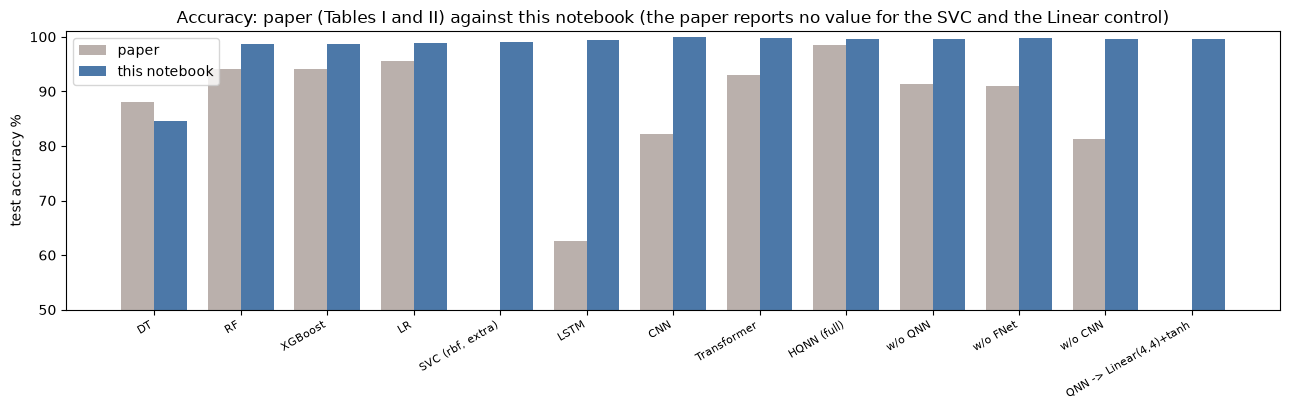

In [13]:
PAPER_T1 = {  # accuracy %, recall %, precision %, F1, time ms for 5 samples
    "DT": (88.11, 86.14, 83.65, 0.8488, None), "RF": (94.12, 98.54, 86.54, 0.9215, None), "XGBoost": (94.12, 91.35, 93.75, 0.9253, None),
    "LR": (95.52, 88.78, 100.00, 0.9406, None), "LSTM": (62.66, 6.73, 95.45, 0.1257, 278.9), "CNN": (82.10, 55.13, 100.00, 0.7108, 174.7),
    "Transformer": (93.09, 82.69, 100.00, 0.9052, 269.5), "baseline [12]": (100.00, 100.00, 100.00, 1.0000, 622.9),
    "HQNN (full)": (98.47, 96.15, 100.00, 0.9804, 485.0)}
PAPER_T2 = {"w/o QNN": (91.43, 78.85, 99.60, 0.8801, 180.7), "w/o FNet": (91.05, 77.56, 100.00, 0.8736, 223.2), "w/o CNN": (81.20, 55.13, 96.09, 0.7006, 223.5)}
PAPER_ALL = {**PAPER_T1, **PAPER_T2}

def mean_of(name, key):
    v = [r[key] for r in RESULTS[name] if r.get(key) is not None]
    return float(np.mean(v)) if v else None
def fmt(name, key, nd=2):
    v = [r[key] for r in RESULTS.get(name, []) if r.get(key) is not None]
    if not v: return "-"
    return f"{np.mean(v):.{nd}f}" + (f" +/- {np.std(v):.{nd}f}" if len(v) > 1 else "")

def table(names, convention="paper"):
    rec, prec, f1 = ("rec_paper", "prec_paper", "f1_paper") if convention == "paper" else ("rec_att", "prec_att", "f1_att")
    rows = []
    for n in names:
        if n not in RESULTS: continue
        p = PAPER_ALL.get(n)
        rows.append({"model": n, "runs": len(RESULTS[n]),
                     "acc % (ours)": fmt(n, "acc"), "acc % (paper)": p[0] if p else "-",
                     "recall % (ours)": fmt(n, rec), "recall % (paper)": p[1] if p and convention == "paper" else "-",
                     "precision % (ours)": fmt(n, prec), "precision % (paper)": p[2] if p and convention == "paper" else "-",
                     "F1 (ours)": fmt(n, f1, 4), "F1 (paper)": p[3] if p and convention == "paper" else "-",
                     "ms/5 samples (ours, median)": fmt(n, "ms", 1), "ms (paper)": (p[4] if p and p[4] else "-")})
    return pd.DataFrame(rows)

TABLE1_NAMES = ["DT", "RF", "XGBoost", "LR", "SVC (rbf, extra)", "LSTM", "CNN", "Transformer", "HQNN (full)"]
TABLE2_NAMES = ["w/o QNN", "w/o FNet", "w/o CNN", "QNN -> Linear(4,4)+tanh"]
print("Table I (paper convention: normal = positive class)"); display(table(TABLE1_NAMES))
print("Table II, ablations (HQNN row repeated for reference)"); display(table(["HQNN (full)"] + TABLE2_NAMES))
print("Same runs, attack as the positive class"); display(table(TABLE1_NAMES + TABLE2_NAMES, "attack")[["model", "acc % (ours)", "recall % (ours)", "precision % (ours)", "F1 (ours)"]])

fig, ax = plt.subplots(figsize=(13, 4.2))
names = [n for n in TABLE1_NAMES + TABLE2_NAMES if n in RESULTS]
x = np.arange(len(names)); w = 0.38
ax.bar(x - w / 2, [PAPER_ALL[n][0] if n in PAPER_ALL else np.nan for n in names], w, label="paper", color="#bab0ac")
ax.bar(x + w / 2, [mean_of(n, "acc") for n in names], w, label="this notebook", color="#4c78a8")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8); ax.set_ylabel("test accuracy %"); ax.set_ylim(50, 101); ax.legend()
ax.set_title("Accuracy: paper (Tables I and II) against this notebook (the paper reports no value for the SVC and the Linear control)")
plt.tight_layout(); plt.show()

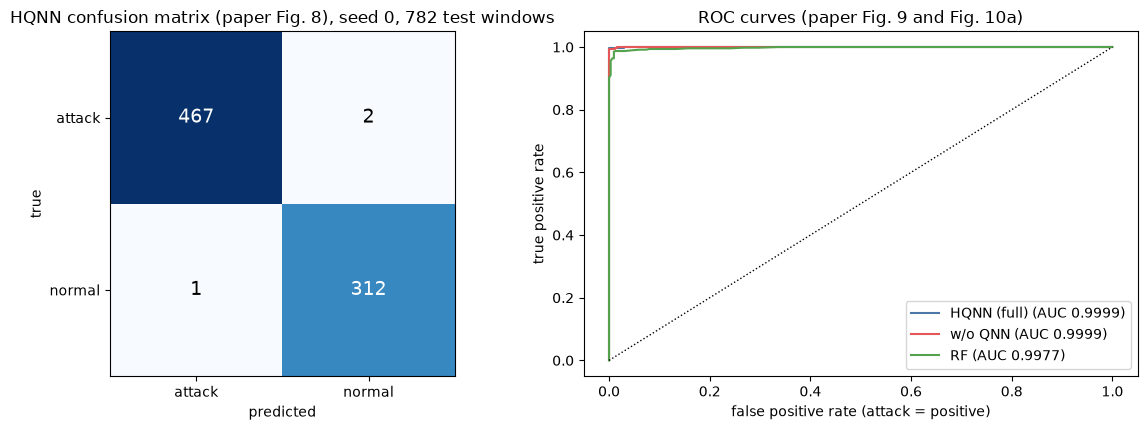

attack windows detected 467, missed 2; normal windows passed 312, false alarms 1


In [14]:
# Fig. 8 (confusion matrix) and Fig. 9 (ROC curve) of the HQNN, first seed, plus the same for two reference models
r0 = RESULTS["HQNN (full)"][0]
cm = confusion_matrix(r0["y"], r0["pred"], labels=[1, 0])                    # rows/cols: attack, normal (attack = positive)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): ax[0].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["attack", "normal"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["attack", "normal"])
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title(f"HQNN confusion matrix (paper Fig. 8), seed {r0['seed']}, {len(r0['y'])} test windows")
for nm, c in [("HQNN (full)", "#4c78a8"), ("w/o QNN", "#e45756"), ("RF", "#54a24b")]:
    if nm in RESULTS:
        rr = RESULTS[nm][0]; fpr, tpr, _ = roc_curve(rr["y"], rr["score"]); ax[1].plot(fpr, tpr, color=c, label=f"{nm} (AUC {roc_auc_score(rr['y'], rr['score']):.4f})")
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("false positive rate (attack = positive)"); ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC curves (paper Fig. 9 and Fig. 10a)"); ax[1].legend(loc="lower right"); plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm[1, 1], cm[1, 0], cm[0, 1], cm[0, 0]
print(f"attack windows detected {tp}, missed {fn}; normal windows passed {tn}, false alarms {fp}")

## 7. Inside the network: convergence and what the quantum circuit sees

The abstract claims faster convergence. The curves below show the training loss and the test accuracy after every epoch (mean over the seeds of each variant). The
second figure shows the **actual angles that enter the circuit** of the first Block: `f(x) = arcsin(tanh(x))` for the 4 qubits, averaged over the 64 time steps of each real
window and coloured by the window's ground-truth traffic class (the trained seed-0 HQNN).

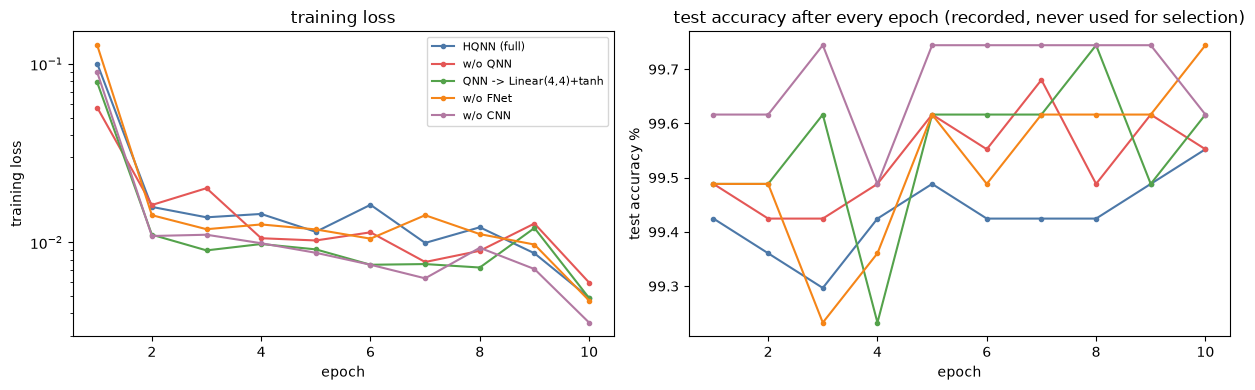

,loss_ep1,acc_ep1,first_epoch_acc90,first_epoch_acc95,final_loss
HQNN (full),0.1005,99.4246,1.0,1.0,0.0049
w/o QNN,0.0570,99.4885,1.0,1.0,0.0059
"QNN -> Linear(4,4)+tanh",0.0788,99.4885,1.0,1.0,0.0049
w/o FNet,0.1275,99.4885,1.0,1.0,0.0047
w/o CNN,0.0899,99.6164,1.0,1.0,0.0035


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for nm, c in [("HQNN (full)", "#4c78a8"), ("w/o QNN", "#e45756"), ("QNN -> Linear(4,4)+tanh", "#54a24b"), ("w/o FNet", "#f58518"), ("w/o CNN", "#b279a2")]:
    if nm not in RESULTS: continue
    H = np.array([[h[1:] for h in r["hist"]] for r in RESULTS[nm]])            # runs x epochs x (loss, acc)
    ep = np.arange(1, H.shape[1] + 1)
    ax[0].plot(ep, H[:, :, 0].mean(0), "-o", color=c, label=nm, ms=3); ax[1].plot(ep, H[:, :, 1].mean(0), "-o", color=c, label=nm, ms=3)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_yscale("log"); ax[0].set_title("training loss"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy %"); ax[1].set_title("test accuracy after every epoch (recorded, never used for selection)")
plt.tight_layout(); plt.show()

def first_epoch_at(name, thr):
    out = []
    for r in RESULTS[name]:
        e = [h[0] for h in r["hist"] if h[2] >= thr]
        out.append(e[0] if e else np.nan)
    return float(np.nanmean(out)) if not np.all(np.isnan(out)) else float("nan")
CONV = {n: dict(loss_ep1=np.mean([r["hist"][0][1] for r in RESULTS[n]]), acc_ep1=np.mean([r["hist"][0][2] for r in RESULTS[n]]),
                first_epoch_acc90=first_epoch_at(n, 90.0), first_epoch_acc95=first_epoch_at(n, 95.0), final_loss=np.mean([r["hist"][-1][1] for r in RESULTS[n]]))
        for n in ["HQNN (full)", "w/o QNN", "QNN -> Linear(4,4)+tanh", "w/o FNet", "w/o CNN"] if n in RESULTS}
display(pd.DataFrame(CONV).T.round(4))

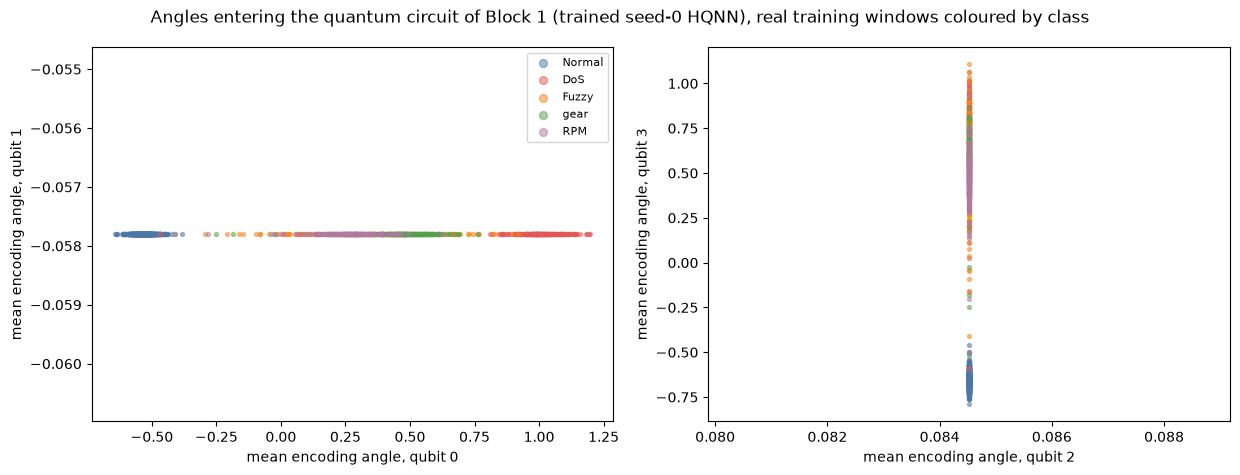

In [16]:
mdl = KEPT["HQNN (full)"]; q1 = mdl.blocks[0].q
sub = np.random.default_rng(SEED).choice(idx_tr, min(1500, len(idx_tr)), replace=False)
mdl.eval(); q1.record = True
with torch.no_grad(): mdl(Xt[torch.from_numpy(sub)])
q1.record = False
ang = (2 * torch.atan(torch.tanh(q1.last_x / 2))).mean(1).numpy()                       # [windows, 4]: mean encoding angle per qubit
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))
for k, (i, j) in enumerate([(0, 1), (2, 3)]):
    for c in CLASSES:
        m = sel_cls[sub] == c
        ax[k].scatter(ang[m, i], ang[m, j], s=8, alpha=0.5, color=COL[c], label=c if k == 0 else None)
    ax[k].set_xlabel(f"mean encoding angle, qubit {i}"); ax[k].set_ylabel(f"mean encoding angle, qubit {j}")
ax[0].legend(markerscale=2, fontsize=8); plt.suptitle("Angles entering the quantum circuit of Block 1 (trained seed-0 HQNN), real training windows coloured by class"); plt.tight_layout(); plt.show()

## 8. Robustness check: a block-wise temporal split

The paper splits its windows at random. Neighbouring windows of the same attack burst are then in both train and test sets, which makes the task easier. As a
harsher check, every capture is cut into 40 contiguous time blocks and **whole blocks are held out**: blocks 3, 11, 19, 27 and 35 are the test blocks, the blocks right next to them are dropped,
and the rest is used for training. Test attacks are then different bursts of injected messages from any training attack. (A simple "train on the first part, test on the last part" split does not work
here: the last part of every capture contains no attack at all.) One run (seed 0) of each model.

In [17]:
for nm, mk in ML_MODELS.items():
    if "SVC" in nm: continue
    run_ml(nm, mk, idx_tr_t, idx_te_t, "temporal")
for nm in ["HQNN (full)", "w/o QNN"]:
    train_torch(nm, VARIANTS[nm][0], idx_tr_t, idx_te_t, 0, split="temporal")
TEMPORAL = [n + " [temporal]" for n in ["DT", "RF", "XGBoost", "LR", "HQNN (full)", "w/o QNN"]]
display(pd.DataFrame([{"model": n.replace(" [temporal]", ""), "acc % temporal": fmt(n, "acc"), "acc % random split": fmt(n.replace(" [temporal]", ""), "acc"),
                       "recall % (normal pos.)": fmt(n, "rec_paper"), "precision % (normal pos.)": fmt(n, "prec_paper"), "attack recall %": fmt(n, "rec_att"), "attack precision %": fmt(n, "prec_att")} for n in TEMPORAL]))
print(f"temporal split: train {len(idx_tr_t)} windows / test {len(idx_te_t)} windows ({int(y_all[idx_te_t].sum())} attack)")

DT             [temporal] acc  79.48 | paper-convention recall  75.46 precision  77.23 F1 0.7633 | 4 s


RF             [temporal] acc  98.19 | paper-convention recall  97.94 precision  97.94 F1 0.9794 | 7 s


XGBoost        [temporal] acc  99.60 | paper-convention recall 100.00 precision  99.09 F1 0.9954 | 24 s


LR             [temporal] acc  99.30 | paper-convention recall 100.00 precision  98.42 F1 0.9920 | 1 s


HQNN (full) [temporal]     seed 0 | acc  99.70 | paper-conv recall 100.00 prec  99.32 F1 0.9966 |   10.9 ms/5 | train    91 s | final loss 0.0049


w/o QNN [temporal]         seed 0 | acc  99.60 | paper-conv recall 100.00 prec  99.09 F1 0.9954 |    3.6 ms/5 | train    45 s | final loss 0.0106


,model,acc % temporal,acc % random split,recall % (normal pos.),precision % (normal pos.),attack recall %,attack precision %
0,DT,79.48,84.65,75.46,77.23,82.62,81.16
1,RF,98.19,98.72,97.94,97.94,98.39,98.39
2,XGBoost,99.60,98.72,100.00,99.09,99.28,100.00
3,LR,99.30,98.85,100.00,98.42,98.75,100.00
4,HQNN (full),99.70,99.55 +/- 0.06,100.00,99.32,99.46,100.00
5,w/o QNN,99.60,99.55 +/- 0.06,100.00,99.09,99.28,100.00


temporal split: train 4914 windows / test 994 windows (558 attack)


## 9. Side by side with the paper: a verdict for every claim

Rule (as for every notebook in this repository): a number is **reproduced** if it lies within 2 points of the paper (0.02 for F1), otherwise **exceeded** or **not reached** with the gap.
Comparison claims are checked on the numbers of this notebook. Single-seed paper numbers are compared with the mean over our seeds.

In [18]:
def verdict_num(ours, paper, tol):
    if ours is None: return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})")

NOISE = 0.5   # accuracy points: about two binomial standard errors of an accuracy near 99 % on 782 test windows (4 windows); smaller gaps are treated as ties
def better(h, others, what="match or beat it"):
    """'reproduced' if h exceeds every value in `others` by more than NOISE points; otherwise 'not reached' and which ones tie or win."""
    worse = [k for k, v in others.items() if h - v <= NOISE]
    if not worse: return "reproduced"
    kinds = ["ties within noise" if abs(h - others[k]) <= NOISE else "is better" for k in worse]
    return "not reached (" + "; ".join(f"{k} {w}" for k, w in zip(worse, kinds)) + ")"

rows = []
def claim(text, paper, ours, verdict):
    rows.append({"claim": text, "paper": paper, "this notebook": ours, "verdict": verdict})

H_ = "HQNN (full)"
for key, lab, tol, idx in [("acc", "accuracy %", 2, 0), ("rec_paper", "recall % (normal positive)", 2, 1), ("prec_paper", "precision % (normal positive)", 2, 2), ("f1_paper", "F1", 0.02, 3)]:
    o = mean_of(H_, key); claim(f"HQNN {lab}", PAPER_T1[H_][idx], None if o is None else round(o, 4), verdict_num(o, PAPER_T1[H_][idx], tol))
for n in ["DT", "RF", "XGBoost", "LR", "LSTM", "CNN", "Transformer"]:
    o = mean_of(n, "acc"); claim(f"{n} accuracy %", PAPER_T1[n][0], None if o is None else round(o, 2), verdict_num(o, PAPER_T1[n][0], 2))
for n in ["w/o QNN", "w/o FNet", "w/o CNN"]:
    o = mean_of(n, "acc"); claim(f"ablation {n}: accuracy %", PAPER_T2[n][0], None if o is None else round(o, 2), verdict_num(o, PAPER_T2[n][0], 2))

h_acc = mean_of(H_, "acc")
trad = {n: mean_of(n, "acc") for n in ["DT", "RF", "XGBoost", "LR"]}
claim("HQNN more accurate than every tree/linear model (DT, RF, XGBoost, LR)", "98.47 > 88.11 / 94.12 / 94.12 / 95.52",
      f"{h_acc:.2f} vs " + " / ".join(f"{v:.2f}" for v in trad.values()), better(h_acc, trad))
deep = {n: mean_of(n, "acc") for n in ["LSTM", "CNN", "Transformer"]}
claim("HQNN more accurate than LSTM, CNN, Transformer", "98.47 > 62.66 / 82.10 / 93.09",
      f"{h_acc:.2f} vs " + " / ".join(f"{v:.2f}" for v in deep.values()), better(h_acc, deep))
ab = {n: mean_of(n, "acc") for n in ["w/o QNN", "w/o FNet", "w/o CNN"]}
claim("every module is indispensable: removing QNN / FNet / CNN lowers accuracy", "98.47 -> 91.43 / 91.05 / 81.20",
      f"{h_acc:.2f} -> " + " / ".join(f"{v:.2f}" for v in ab.values()), better(h_acc, ab, "removing it does not hurt"))
claim("removing the CNN layer hurts most", "81.20 is the lowest ablation", " / ".join(f"{k}: {v:.2f}" for k, v in ab.items()), "reproduced" if min(ab, key=ab.get) == "w/o CNN" and h_acc - ab["w/o CNN"] > NOISE else "not reached (no drop beyond noise; the largest drop is " + min(ab, key=ab.get) + f", {h_acc - min(ab.values()):+.2f} points)")
ctl = mean_of("QNN -> Linear(4,4)+tanh", "acc")
claim("(extra control, not in the paper) the quantum circuit beats a classical Linear(4,4)+tanh layer in the same place", "not tested", f"{h_acc:.2f} vs {ctl:.2f}",
      "reproduced" if h_acc - ctl > NOISE else "no quantum advantage here (tie within noise, gap " + f"{h_acc - ctl:+.2f} points)" if abs(h_acc - ctl) <= NOISE else "classical control is better (" + f"{h_acc - ctl:+.2f} points)")
t_h, t_n = mean_of(H_, "ms"), mean_of("w/o QNN", "ms")
claim("the QNN layer costs inference time when simulated classically (w/o QNN is faster)", "485.0 ms vs 180.7 ms (2.7 x)", f"{t_h:.1f} ms vs {t_n:.1f} ms ({t_h / t_n:.1f} x)", "reproduced" if t_h > t_n else "not reached")
claim("HQNN inference time 485.0 ms for 5 samples", 485.0, f"{t_h:.1f} ms on this CPU (PyTorch simulator)", "cannot be checked (hardware dependent)")
claim("HQNN faster than baseline [12] (622.9 ms) with F1 0.9804 vs 1.0000", "485.0 ms vs 622.9 ms", "baseline [12] is another paper and is not re-implemented", "cannot be checked")
c_h, c_n = CONV["HQNN (full)"], CONV["w/o QNN"]
claim("HQNN converges faster (abstract)", "no number given", f"epoch to reach 95 % test accuracy: HQNN {c_h['first_epoch_acc95']:.1f}, w/o QNN {c_n['first_epoch_acc95']:.1f}; loss after epoch 1: {c_h['loss_ep1']:.3f} vs {c_n['loss_ep1']:.3f}",
      "reproduced" if (c_h['first_epoch_acc95'] < c_n['first_epoch_acc95'] or (c_h['loss_ep1'] < c_n['loss_ep1'] and not np.isnan(c_h['first_epoch_acc95']))) else "not reached (no faster convergence than the network without the circuit)")
VERDICTS = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
display(VERDICTS)
print("\nverdict counts:", dict(VERDICTS["verdict"].str.replace(r"\s*\(.*$", "", regex=True).value_counts()))
print(f"total notebook run time so far: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min | FAST_MODE = {FAST_MODE}")

,claim,paper,this notebook,verdict
0,HQNN accuracy %,98.47,99.5524,reproduced
1,HQNN recall % (normal positive),96.15,99.8403,exceeded (+3.69)
2,HQNN precision % (normal positive),100.0,99.0506,reproduced
3,HQNN F1,0.9804,0.9944,reproduced
4,DT accuracy %,88.11,84.65,not reached (-3.46)
5,RF accuracy %,94.12,98.72,exceeded (+4.60)
6,XGBoost accuracy %,94.12,98.72,exceeded (+4.60)
7,LR accuracy %,95.52,98.85,exceeded (+3.33)
8,LSTM accuracy %,62.66,99.36,exceeded (+36.70)
9,CNN accuracy %,82.1,99.87,exceeded (+17.77)



verdict counts: {'exceeded': np.int64(10), 'reproduced': np.int64(5), 'not reached': np.int64(5), 'cannot be checked': np.int64(2), 'no quantum advantage here': np.int64(1)}
total notebook run time so far: 26.7 min | FAST_MODE = False


## 10. Reading the paper critically

**What this notebook found (full run, 7,812 windows, 782 test windows, 2 seeds for the HQNN).**

| Model | Accuracy % |
|---|---|
| HQNN (full) | 99.55 +/- 0.06 |
| without QNN layer | 99.55 +/- 0.06 |
| without FNet | 99.74 (1 seed) |
| without CNN | 99.62 (1 seed) |
| QNN replaced by `tanh(Linear(4,4))` (control) | 99.62 (1 seed) |
| DT / RF / XGBoost / LR / SVC | 84.65 / 98.72 / 98.72 / 98.85 / 98.98 |
| LSTM / CNN / Transformer | 99.36 / 99.87 / 99.74 |

On the paper's own task definition the HQNN is as good as the paper says (99.55 % against 98.47 %; one test window is 0.13 points, so differences below about 0.5 points are
noise), **but almost every other model is as good, including the ones the paper reports as poor.**

1. **The comparison claims do not survive an equal footing.** The paper's LSTM (62.66 %), CNN (82.10 %) and Transformer (93.09 %) are far below
   what the same kinds of network reach here on the same 64 x 49 windows (99.36 %, 99.87 %, 99.74 % after 10 epochs with ordinary settings). The
   paper does not give their architectures, optimiser or epochs, and a model that stays at 62.66 % accuracy with 6.73 % recall looks under-trained rather than weak. The HQNN's lead over
   them is a statement about how the baselines were trained, not about quantum circuits.
2. **The ablations do not reproduce.** Removing the QNN layer changes the accuracy from 99.55 to 99.55 %, removing FNet to 99.74 %, removing the CNN layer to 99.62 %
   (paper: 91.43 %, 91.05 %, 81.20 %). All gaps are within one or two test windows. "Each module is indispensable" and "the CNN matters most" are not supported on this data.
3. **The quantum layer does no work that a small classical layer cannot do.** Replacing it by `tanh(Linear(4,4))` gives 99.62 % (99.55 % with the circuit). The circuit is a
   fixed-form function of 4 inputs with 8 parameters, built from real gates only (`Ry`, CNOT), so its 4 outputs are smooth trigonometric polynomials of the inputs; the encoding `Ry(f(x))`
   is immediately followed by a trainable `Ry(theta)` on the same qubit, which just adds the two angles. In the trained network the angle scatter plot of section 7 shows that in Block 1 only two of
   the four qubits carry a signal: the other two inputs are constant (those channels carry no window-dependent signal, only the batch-norm offset is left; why, for example a dead ReLU channel, is not investigated here).
4. **Inference time: the paper's own trade-off is confirmed, its motivation is not.** With the circuit simulated classically the network is about 2.4 times slower
   (median 9.9 ms against 4.2 ms for 5 samples; the paper: 485.0 ms against 180.7 ms, 2.7 times). The abstract says the quantum circuit "improves detection time", but on a classical simulator it can only
   add time, and no real quantum hardware was used. The paper's comparison with baseline [12] (485.0 ms against 622.9 ms) compares two different networks on unknown hardware and cannot be checked here.
5. **Convergence.** All variants reach more than 95 % test accuracy after the first epoch, and the network without the circuit has the lower loss after one epoch (0.057 against 0.101). The claim of faster convergence is not supported.
6. **A harder split gives the same picture.** Holding out whole contiguous stretches of every capture (section 8) leaves the HQNN at 99.70 % and the network without the circuit at 99.60 %
   (XGBoost 99.60 %, LR 99.30 %, RF 98.19 %, DT 79.48 %), so the high accuracies are not an artefact of neighbouring windows from the same attack burst sitting in both train and test sets.
7. **Why the task is easy.** A window counts as attack if it contains one injected message; DoS, gear and RPM attacks inject a message every 0.3 to 1 ms, so most attack windows are dominated by a single
   forged ID (`0x000` for DoS) and the 49-bit ID encoding already separates them. The only hard cases are windows at the edge of an attack burst, which is where the few errors of every model sit
   (seed-0 HQNN: 2 missed attack windows and 1 false alarm out of 782).
8. **What the paper leaves open.** Epochs, optimiser, batch size, how the 7,812 samples were drawn, the window labelling rule, the `arcsin` domain problem for batch-normalised inputs, the Conv1D padding, the
   separation of the two PQC layers' parameters, the architecture of every baseline and the timing hardware. Table I is only self-consistent if precision / recall refer to the class labelled 1 (normal); with the usual security
   convention (attack positive) the same HQNN has 99.36 % attack recall and 99.89 % attack precision here. One run, one split and a 782-window test set also leave an uncertainty of about +/- 0.5 points on every accuracy.

**Bottom line.** The architecture can be built and trained as described, and it reaches the accuracy the paper reports, but on this data the quantum layer neither improves accuracy nor
speed, and the claimed advantages over the other models and over the ablated variants come from baselines that are far weaker in the paper than they are when trained normally.

## 11. Exercises

1. **Harder labels.** Change the window label from "at least one injected message" to "more than 8 injected messages" (or to the *first* injected message of a burst) and
   re-run sections 2 to 9. Which models break first? Is there now a gap between the HQNN and the tree models?
2. **Starve the models.** Train on only 100, 300 and 1,000 training windows (keep the test set). Compare the HQNN, the network without the circuit and the `Linear(4,4)` control. Does the
   quantum layer help when data are scarce?
3. **Take the entanglement away.** Remove the CNOT ring from `qnn_circuit` and from `TorchQNN` (the ring permutation `P`), keep the equivalence test, and retrain. How many parameters does the
   PQC need to produce a useful non-linearity? Where does the accuracy change, if at all?
4. **Wake up the idle qubits.** In Block 1 only two of the four qubits carry a signal. Find out why (inspect the Conv1D + ReLU outputs per channel), try removing the ReLU or adding a `LeakyReLU`, and look at the angle scatter plot again. Does
   the network use all four qubits now, and does it matter?
5. **Noise and shots.** Re-evaluate the trained circuits with `qml.device("default.mixed")` and depolarising noise of 1 %, 2 % and 5 % per gate, and with a finite number of shots, using the QNode of section
   "Quantum Circuit Architecture". How much accuracy is lost, and how many shots does a 99 % result need?